# Why did SMOTENC change accuracy more than F1 or PR-AUC?

This investigation reproduces the **post-call** UCI Bank Marketing experiment (dataset 222, with completed-call `duration`) on the same stratified 60/20/20 split, seed 42, and 5,000 synthetic subscriber rows as the baseline notebooks. Positive class: `y = yes`. All learned preprocessing and sampling are fitted on training rows only. Validation is used to compare methods and tune one cutoff; the test split is reported as a descriptive, untouched check. Test results are not used to select a method or cutoff.

Run from the repository root or this notebook's directory in an environment with the project dependencies. The UCI API fetch requires internet access. This notebook follows the existing eight-model architecture and metric definitions; Noor's PR #30 was unavailable when it was written.


In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from imblearn.over_sampling import ADASYN, BorderlineSMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, auc, brier_score_loss, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score)
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier

root = Path.cwd()
while not (root / "pyproject.toml").exists():
    if root == root.parent:
        raise RuntimeError("Run from inside the project repository")
    root = root.parent
sys.path.insert(0, str(root / "eda/baseline-modeling/uci_banking"))
from scripts.uci_preprocessing import load_and_preprocess_uci
from scripts.uci_preprocessing_smotenc import make_smotenc_model_pipeline

SEED = 42
N_SYNTHETIC = 5000
METRICS = ["accuracy", "f1", "precision", "recall", "pr_auc", "brier"]
pd.options.display.float_format = "{:.4f}".format
data = load_and_preprocess_uci(seed=SEED, include_duration=True)
X_train, X_val, X_test = data.X_train, data.X_val, data.X_test
y_train, y_val, y_test = data.y_train, data.y_val, data.y_test
preprocessor = data.preprocessor
counts = y_train.value_counts()
smotenc_ratio = (int(counts.loc[1]) + N_SYNTHETIC) / int(counts.loc[0])
print("Split sizes:", {"train": len(y_train), "validation": len(y_val), "test": len(y_test)})
print("Training prevalence:", round(y_train.mean(), 4), "SMOTENC target minority/majority ratio:", round(smotenc_ratio, 4))
assert "duration" in X_train.columns
assert X_train.index.is_unique and not X_train.index.intersection(X_val.index).size
assert not X_train.index.intersection(X_test.index).size


Split sizes: {'train': 27126, 'validation': 9042, 'test': 9043}
Training prevalence: 0.117 SMOTENC target minority/majority ratio: 0.3412


In [2]:
def pr_auc(y, p):
    precision, recall, _ = precision_recall_curve(y, p)
    return auc(recall, precision)  # Matches the two source notebooks (trapezoidal PR-AUC).


def score(y, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y, pred),
        "f1": f1_score(y, pred, zero_division=0),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "pr_auc": pr_auc(y, p),
        "brier": brier_score_loss(y, p),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "predicted_yes": int(pred.sum()),
        "mean_probability": float(np.mean(p)),
    }


def make_models():
    models = {
        "Logistic regression": LogisticRegression(max_iter=1000, random_state=SEED),
        "Decision tree": DecisionTreeClassifier(random_state=SEED),
        "Random forest": RandomForestClassifier(n_estimators=100, n_jobs=2, random_state=SEED),
        "Gradient boosting": GradientBoostingClassifier(random_state=SEED),
        "XGBoost": xgb.XGBClassifier(n_estimators=150, n_jobs=2, random_state=SEED),
        "LightGBM": lgb.LGBMClassifier(n_estimators=150, verbosity=-1, n_jobs=2, random_state=SEED),
        "CatBoost": CatBoostClassifier(iterations=200, thread_count=2, verbose=0,
                                        random_seed=SEED, allow_writing_files=False),
    }
    return models


def stacking(models, smotenc=False):
    names = [("logistic", "Logistic regression"), ("forest", "Random forest"),
             ("lightgbm", "LightGBM")]
    estimators = [(short, make_smotenc_model_pipeline(models[long], preprocessor,
                   X_train, smotenc_ratio, SEED) if smotenc else clone(models[long]))
                  for short, long in names]
    return StackingClassifier(
        estimators=estimators,
        final_estimator=LogisticRegression(max_iter=1000, random_state=SEED),
        stack_method="predict_proba", cv=3, n_jobs=1,
    )


models = make_models()
models["Stacking ensemble"] = stacking(models)


## Paired eight-model comparison

Each architecture is fitted twice on the same training customers: original rows, and fold-safe SMOTENC. For stacking, the SMOTENC sampler is inside each base estimator, including the stack's internal training folds, matching the source notebook. The table includes **every model on both validation and test**, rather than only the selected winner. Differences are SMOTENC minus baseline; lower Brier score is better. Test values are diagnostic, not a selection criterion.


In [3]:
rows = []
probabilities = {}
for name, model in models.items():
    for method in ("Baseline", "SMOTENC"):
        if method == "Baseline":
            pipeline = make_pipeline(clone(preprocessor), clone(model))
        elif name == "Stacking ensemble":
            pipeline = stacking(make_models(), smotenc=True)
        else:
            pipeline = make_smotenc_model_pipeline(model, preprocessor, X_train,
                                                   smotenc_ratio, SEED)
        pipeline.fit(X_train, y_train)
        for split, X, y in (("validation", X_val, y_val), ("test", X_test, y_test)):
            p = pipeline.predict_proba(X)[:, 1]
            probabilities[(name, method, split)] = p
            rows.append({"model": name, "method": method, "split": split, **score(y, p)})
        print("Finished", name, method, flush=True)

results = pd.DataFrame(rows).set_index(["model", "method", "split"]).sort_index()
for split in ("validation", "test"):
    base = results.xs(("Baseline", split), level=("method", "split"))
    smote = results.xs(("SMOTENC", split), level=("method", "split"))
    delta = smote[METRICS + ["fp", "tp"]] - base[METRICS + ["fp", "tp"]]
    print(f"\n{split.title()}: SMOTENC minus baseline (positive delta is not always better)")
    display(delta.round(4))
    print("Absolute scores (baseline then SMOTENC):")
    display(results.xs(split, level="split")[METRICS + ["tn", "fp", "fn", "tp"]].round(4))


Finished Logistic regression Baseline


Finished Logistic regression SMOTENC


Finished Decision tree Baseline


Finished Decision tree SMOTENC


Finished Random forest Baseline


...

accuracy     f1  precision  recall  pr_auc  \
model               method                                                 
CatBoost            Baseline    0.9081 0.5466     0.6465  0.4735  0.6098   
                    SMOTENC     0.9117 0.5990     0.6395  0.5633  0.6182   
Decision tree       Baseline    0.8775 0.4739     0.4761  0.4716  0.5048   
                    SMOTENC     0.8676 0.4649     0.4411  0.4915  0.4960   
Gradient boosting   Baseline    0.9064 0.5000     0.6672  0.3998  0.5887   
                    SMOTENC     0.8989 0.5733     0.5664  0.5803  0.5647   
LightGBM            Baseline    0.9081 0.5432     0.6491  0.4669  0.6209   
                    SMOTENC     0.9099 0.6053     0.6207  0.5907  0.6078   
Logistic regression Baseline    0.9019 0.4562     0.6492  0.3516  0.5500   
                    SMOTENC     0.8978 0.5730     0.5606  0.5860  0.5364   
Random forest       Baseline    0.9050 0.4902     0.6587  0.3904  0.6096   
                    SMOTENC     0.9023 0.5678     0.5888  0.5482  0.5930   
Stacking ensemble   Baseline    0.9093 0.5439     0.6608  0.4622  0.6291   
                    SMOTENC     0.9088 0.5538     0.6473  0.4839  0.6184   
XGBoost             Baseline    0.9062 0.5465     0.6293  0.4830  0.6040   
                    SMOTENC     0.9023 0.5749     0.5859  0.5643  0.5840   

                              brier    tn   fp   fn   tp  
model               method                                
CatBoost            Baseline 0.0630  7710  274  557  501  
                    SMOTENC  0.0632  7648  336  462  596  
Decision tree       Baseline 0.1225  7435  549  559  499  
                    SMOTENC  0.1324  7325  659  538  520  
Gradient boosting   Baseline 0.0664  7773  211  635  423  
                    SMOTENC  0.0711  7514  470  444  614  
LightGBM            Baseline 0.0625  7717  267  564  494  
                    SMOTENC  0.0642  7602  382  433  625  
Logistic regression Baseline 0.0714  7783  201  686  372  
                    SMOTENC  0.0790  7498  486  438  620  
Random forest       Baseline 0.0642  7770  214  645  413  
                    SMOTENC  0.0675  7579  405  478  580  
Stacking ensemble   Baseline 0.0646  7733  251  569  489  
                    SMOTENC  0.0649  7705  279  546  512  
XGBoost             Baseline 0.0654  7683  301  547  511  
                    SMOTENC  0.0684  7562  422  461  597


Test: SMOTENC minus baseline (positive delta is not always better)


,accuracy,f1,precision,recall,pr_auc,brier,fp,tp
model,,,,,,,,
CatBoost,-0.0013,0.0329,-0.0391,0.0775,-0.0021,0.0005,94,82
Decision tree,-0.0015,0.0246,-0.0021,0.0567,0.0240,0.0015,74,60
Gradient boosting,-0.0033,0.0830,-0.0848,0.1824,-0.0075,0.0034,223,193
LightGBM,-0.0035,0.0330,-0.0514,0.0926,-0.0009,0.0013,130,98
Logistic regression,-0.0074,0.1065,-0.1163,0.2268,-0.0168,0.0073,307,240
Random forest,-0.0065,0.0519,-0.0914,0.1352,-0.0256,0.0033,202,143
Stacking ensemble,-0.0034,-0.0030,-0.0311,0.0123,-0.0142,0.0012,44,13
XGBoost,-0.0040,0.0189,-0.0439,0.0633,-0.0023,0.0015,103,67


Absolute scores (baseline then SMOTENC):


accuracy     f1  precision  recall  pr_auc  \
model               method                                                 
CatBoost            Baseline    0.9119 0.5604     0.6728  0.4802  0.6438   
                    SMOTENC     0.9105 0.5933     0.6337  0.5577  0.6417   
Decision tree       Baseline    0.8749 0.4757     0.4668  0.4849  0.5060   
                    SMOTENC     0.8734 0.5002     0.4647  0.5416  0.5300   
Gradient boosting   Baseline    0.9079 0.5074     0.6777  0.4055  0.6174   
                    SMOTENC     0.9046 0.5904     0.5929  0.5879  0.6100   
LightGBM            Baseline    0.9104 0.5603     0.6582  0.4877  0.6362   
                    SMOTENC     0.9069 0.5932     0.6067  0.5803  0.6352   
Logistic regression Baseline    0.9038 0.4583     0.6715  0.3478  0.5599   
                    SMOTENC     0.8964 0.5648     0.5553  0.5747  0.5431   
Random forest       Baseline    0.9090 0.5196     0.6794  0.4206  0.6335   
                    SMOTENC     0.9025 0.5714     0.5880  0.5558  0.6080   
Stacking ensemble   Baseline    0.9110 0.5550     0.6684  0.4745  0.6502   
                    SMOTENC     0.9076 0.5520     0.6374  0.4868  0.6360   
XGBoost             Baseline    0.9094 0.5618     0.6473  0.4962  0.6113   
                    SMOTENC     0.9055 0.5807     0.6035  0.5595  0.6091   

                              brier    tn   fp   fn   tp  
model               method                                
CatBoost            Baseline 0.0606  7738  247  550  508  
                    SMOTENC  0.0611  7644  341  468  590  
Decision tree       Baseline 0.1251  7399  586  545  513  
                    SMOTENC  0.1266  7325  660  485  573  
Gradient boosting   Baseline 0.0640  7781  204  629  429  
                    SMOTENC  0.0674  7558  427  436  622  
LightGBM            Baseline 0.0608  7717  268  542  516  
                    SMOTENC  0.0620  7587  398  444  614  
Logistic regression Baseline 0.0701  7805  180  690  368  
                    SMOTENC  0.0775  7498  487  450  608  
Random forest       Baseline 0.0623  7775  210  613  445  
                    SMOTENC  0.0656  7573  412  470  588  
Stacking ensemble   Baseline 0.0626  7736  249  556  502  
                    SMOTENC  0.0638  7692  293  543  515  
XGBoost             Baseline 0.0651  7699  286  533  525  
                    SMOTENC  0.0666  7596  389  466  592

## Did extra false positives explain the accuracy change?

Rows below show precision/recall and the full confusion matrix at the same 0.5 cutoff. The matrix is `[[TN, FP], [FN, TP]]` with `yes` as positive. Accuracy can fall when added FP outnumber recovered TP; F1 can remain close because recall rises while precision falls. PR-AUC uses the full ranked probability curve and is independent of the 0.5 cutoff. This hypothesis is checked for each model rather than assumed from the winning stack.


In [4]:
confusion = results[["accuracy", "f1", "precision", "recall", "pr_auc",
                     "tn", "fp", "fn", "tp", "predicted_yes"]]
for split in ("validation", "test"):
    print(split.title())
    display(confusion.xs(split, level="split").round(4))


Validation


accuracy     f1  precision  recall  pr_auc  \
model               method                                                 
CatBoost            Baseline    0.9081 0.5466     0.6465  0.4735  0.6098   
                    SMOTENC     0.9117 0.5990     0.6395  0.5633  0.6182   
Decision tree       Baseline    0.8775 0.4739     0.4761  0.4716  0.5048   
                    SMOTENC     0.8676 0.4649     0.4411  0.4915  0.4960   
Gradient boosting   Baseline    0.9064 0.5000     0.6672  0.3998  0.5887   
                    SMOTENC     0.8989 0.5733     0.5664  0.5803  0.5647   
LightGBM            Baseline    0.9081 0.5432     0.6491  0.4669  0.6209   
                    SMOTENC     0.9099 0.6053     0.6207  0.5907  0.6078   
Logistic regression Baseline    0.9019 0.4562     0.6492  0.3516  0.5500   
                    SMOTENC     0.8978 0.5730     0.5606  0.5860  0.5364   
Random forest       Baseline    0.9050 0.4902     0.6587  0.3904  0.6096   
                    SMOTENC     0.9023 0.5678     0.5888  0.5482  0.5930   
Stacking ensemble   Baseline    0.9093 0.5439     0.6608  0.4622  0.6291   
                    SMOTENC     0.9088 0.5538     0.6473  0.4839  0.6184   
XGBoost             Baseline    0.9062 0.5465     0.6293  0.4830  0.6040   
                    SMOTENC     0.9023 0.5749     0.5859  0.5643  0.5840   

                                tn   fp   fn   tp  predicted_yes  
model               method                                        
CatBoost            Baseline  7710  274  557  501            775  
                    SMOTENC   7648  336  462  596            932  
Decision tree       Baseline  7435  549  559  499           1048  
                    SMOTENC   7325  659  538  520           1179  
Gradient boosting   Baseline  7773  211  635  423            634  
                    SMOTENC   7514  470  444  614           1084  
LightGBM            Baseline  7717  267  564  494            761  
                    SMOTENC   7602  382  433  625           1007  
Logistic regression Baseline  7783  201  686  372            573  
                    SMOTENC   7498  486  438  620           1106  
Random forest       Baseline  7770  214  645  413            627  
                    SMOTENC   7579  405  478  580            985  
Stacking ensemble   Baseline  7733  251  569  489            740  
                    SMOTENC   7705  279  546  512            791  
XGBoost             Baseline  7683  301  547  511            812  
                    SMOTENC   7562  422  461  597           1019

Test


accuracy     f1  precision  recall  pr_auc  \
model               method                                                 
CatBoost            Baseline    0.9119 0.5604     0.6728  0.4802  0.6438   
                    SMOTENC     0.9105 0.5933     0.6337  0.5577  0.6417   
Decision tree       Baseline    0.8749 0.4757     0.4668  0.4849  0.5060   
                    SMOTENC     0.8734 0.5002     0.4647  0.5416  0.5300   
Gradient boosting   Baseline    0.9079 0.5074     0.6777  0.4055  0.6174   
                    SMOTENC     0.9046 0.5904     0.5929  0.5879  0.6100   
LightGBM            Baseline    0.9104 0.5603     0.6582  0.4877  0.6362   
                    SMOTENC     0.9069 0.5932     0.6067  0.5803  0.6352   
Logistic regression Baseline    0.9038 0.4583     0.6715  0.3478  0.5599   
                    SMOTENC     0.8964 0.5648     0.5553  0.5747  0.5431   
Random forest       Baseline    0.9090 0.5196     0.6794  0.4206  0.6335   
                    SMOTENC     0.9025 0.5714     0.5880  0.5558  0.6080   
Stacking ensemble   Baseline    0.9110 0.5550     0.6684  0.4745  0.6502   
                    SMOTENC     0.9076 0.5520     0.6374  0.4868  0.6360   
XGBoost             Baseline    0.9094 0.5618     0.6473  0.4962  0.6113   
                    SMOTENC     0.9055 0.5807     0.6035  0.5595  0.6091   

                                tn   fp   fn   tp  predicted_yes  
model               method                                        
CatBoost            Baseline  7738  247  550  508            755  
                    SMOTENC   7644  341  468  590            931  
Decision tree       Baseline  7399  586  545  513           1099  
                    SMOTENC   7325  660  485  573           1233  
Gradient boosting   Baseline  7781  204  629  429            633  
                    SMOTENC   7558  427  436  622           1049  
LightGBM            Baseline  7717  268  542  516            784  
                    SMOTENC   7587  398  444  614           1012  
Logistic regression Baseline  7805  180  690  368            548  
                    SMOTENC   7498  487  450  608           1095  
Random forest       Baseline  7775  210  613  445            655  
                    SMOTENC   7573  412  470  588           1000  
Stacking ensemble   Baseline  7736  249  556  502            751  
                    SMOTENC   7692  293  543  515            808  
XGBoost             Baseline  7699  286  533  525            811  
                    SMOTENC   7596  389  466  592            981

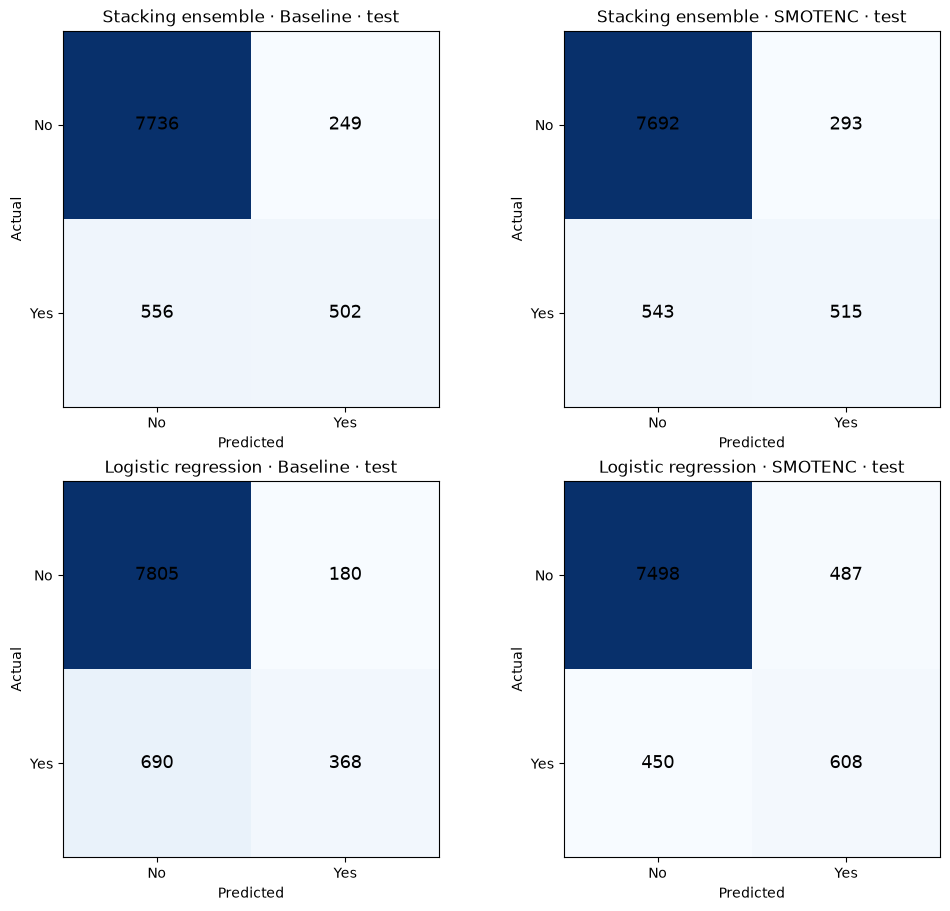

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9), layout="constrained")
for row, name in enumerate(("Stacking ensemble", "Logistic regression")):
    for col, method in enumerate(("Baseline", "SMOTENC")):
        p = probabilities[(name, method, "test")]
        matrix = confusion_matrix(y_test, p >= 0.5, labels=[0, 1])
        ax = axes[row, col]
        ax.imshow(matrix, cmap="Blues")
        for (i, j), value in np.ndenumerate(matrix):
            ax.text(j, i, str(value), ha="center", va="center", fontsize=13)
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["No", "Yes"],
               yticklabels=["No", "Yes"], xlabel="Predicted", ylabel="Actual",
               title=f"{name} · {method} · test")
plt.show()


## Probability calibration

Brier score (smaller is better) and reliability curves assess whether the predicted probabilities match observed subscriber rates. A lower accuracy after oversampling may also reflect shifted probabilities and a mismatched 0.5 cutoff. Reliability bins are summaries, not proof of calibration for sparse high-score bins.


brier  mean_probability  \
model               method   split                                 
CatBoost            Baseline test       0.0606            0.1128   
                             validation 0.0630            0.1154   
                    SMOTENC  test       0.0611            0.1285   
                             validation 0.0632            0.1300   
Decision tree       Baseline test       0.1251            0.1215   
                             validation 0.1225            0.1159   
                    SMOTENC  test       0.1266            0.1363   
                             validation 0.1324            0.1304   
Gradient boosting   Baseline test       0.0640            0.1152   
                             validation 0.0664            0.1165   
                    SMOTENC  test       0.0674            0.1619   
                             validation 0.0711            0.1636   
LightGBM            Baseline test       0.0608            0.1127   
                             validation 0.0625            0.1136   
                    SMOTENC  test       0.0620            0.1321   
                             validation 0.0642            0.1344   
Logistic regression Baseline test       0.0701            0.1149   
                             validation 0.0714            0.1170   
                    SMOTENC  test       0.0775            0.1841   
                             validation 0.0790            0.1861   
Random forest       Baseline test       0.0623            0.1153   
                             validation 0.0642            0.1165   
                    SMOTENC  test       0.0656            0.1477   
                             validation 0.0675            0.1489   
Stacking ensemble   Baseline test       0.0626            0.1170   
                             validation 0.0646            0.1172   
                    SMOTENC  test       0.0638            0.1175   
                             validation 0.0649            0.1186   
XGBoost             Baseline test       0.0651            0.1103   
                             validation 0.0654            0.1108   
                    SMOTENC  test       0.0666            0.1264   
                             validation 0.0684            0.1283   

                                         actual_prevalence  
model               method   split                          
CatBoost            Baseline test                   0.1170  
                             validation             0.1170  
                    SMOTENC  test                   0.1170  
                             validation             0.1170  
Decision tree       Baseline test                   0.1170  
                             validation             0.1170  
                    SMOTENC  test                   0.1170  
                             validation             0.1170  
Gradient boosting   Baseline test                   0.1170  
                             validation             0.1170  
                    SMOTENC  test                   0.1170  
                             validation             0.1170  
LightGBM            Baseline test                   0.1170  
                             validation             0.1170  
                    SMOTENC  test                   0.1170  
                             validation             0.1170  
Logistic regression Baseline test                   0.1170  
                             validation             0.1170  
                    SMOTENC  test                   0.1170  
                             validation             0.1170  
Random forest       Baseline test                   0.1170  
                             validation             0.1170  
                    SMOTENC  test                   0.1170  
                             validation             0.1170  
Stacking ensemble   Baseline test                   0.1170  
                             validation             0.1170  
                    

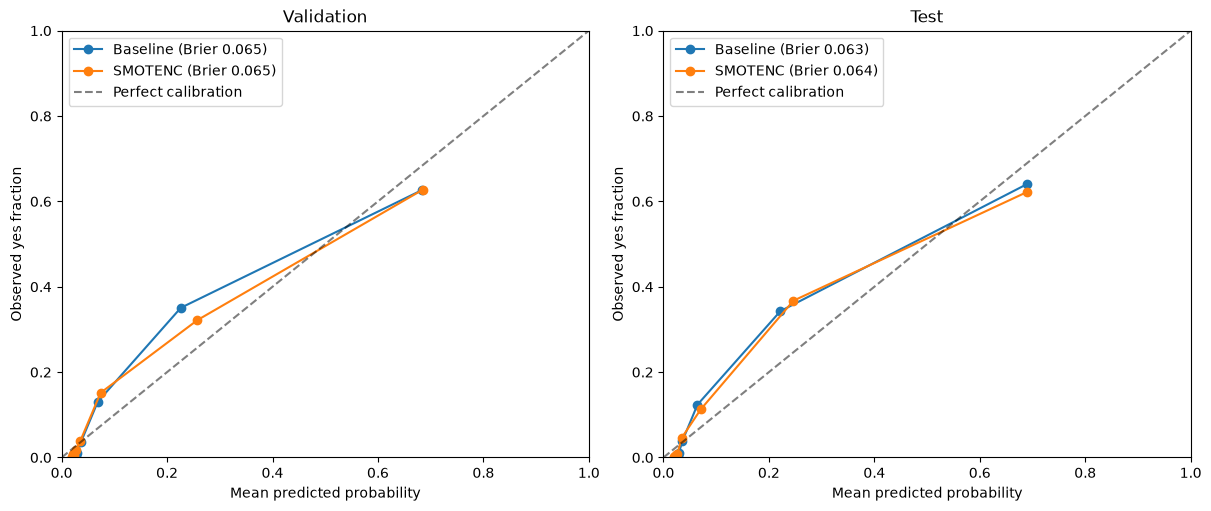

In [6]:
calibration = results[["brier", "mean_probability"]].copy()
calibration["actual_prevalence"] = [float(y_val.mean() if idx[2] == "validation" else y_test.mean())
                                    for idx in calibration.index]
display(calibration.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, split, y in zip(axes, ("validation", "test"), (y_val, y_test)):
    for method in ("Baseline", "SMOTENC"):
        p = probabilities[("Stacking ensemble", method, split)]
        observed, predicted = calibration_curve(y, p, n_bins=10, strategy="quantile")
        ax.plot(predicted, observed, marker="o", label=f"{method} (Brier {brier_score_loss(y, p):.3f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Perfect calibration")
    ax.set(xlabel="Mean predicted probability", ylabel="Observed yes fraction", title=split.title(),
           xlim=(0, 1), ylim=(0, 1))
    ax.legend()
plt.show()


## Other balancing choices: same logistic-regression architecture

To isolate the balancing method, these six comparisons use logistic regression with identical train/validation/test rows and base preprocessing. SMOTENC adds 5,000 positives; ADASYN and BorderlineSMOTE target the same minority/majority ratio. Random undersampling targets that ratio by removing majority rows. Class weighting uses `class_weight='balanced'`. ADASYN and BorderlineSMOTE run **after one-hot encoding**, so their synthetic dummy coordinates can be fractional; they are exploratory model-space methods, not valid synthetic categorical records. SMOTENC handles categories before one-hot encoding. Sampling is never applied to validation or test.

The tuned-cutoff row fits the *baseline* model and picks the validation F1-maximizing threshold. Its PR-AUC and Brier are identical to the baseline because the probabilities are unchanged. No threshold is chosen using test outcomes.


In [7]:
lr = LogisticRegression(max_iter=1000, random_state=SEED)
alternatives = {
    "Baseline": make_pipeline(clone(preprocessor), clone(lr)),
    "SMOTENC": make_smotenc_model_pipeline(lr, preprocessor, X_train, smotenc_ratio, SEED),
    "Class weights": make_pipeline(clone(preprocessor), LogisticRegression(
        max_iter=1000, random_state=SEED, class_weight="balanced")),
    "ADASYN": make_imb_pipeline(clone(preprocessor), ADASYN(
        sampling_strategy=smotenc_ratio, random_state=SEED), clone(lr)),
    "BorderlineSMOTE": make_imb_pipeline(clone(preprocessor), BorderlineSMOTE(
        sampling_strategy=smotenc_ratio, random_state=SEED), clone(lr)),
    "Undersampling": make_imb_pipeline(RandomUnderSampler(
        sampling_strategy=smotenc_ratio, random_state=SEED), clone(preprocessor), clone(lr)),
}
alternative_rows = []
alternative_probabilities = {}
for method, pipeline in alternatives.items():
    pipeline.fit(X_train, y_train)
    for split, X, y in (("validation", X_val, y_val), ("test", X_test, y_test)):
        p = pipeline.predict_proba(X)[:, 1]
        alternative_probabilities[(method, split)] = p
        alternative_rows.append({"method": method, "split": split, "cutoff": 0.5, **score(y, p)})
    print("Finished", method, flush=True)

precision_curve, recall_curve, thresholds = precision_recall_curve(
    y_val, alternative_probabilities[("Baseline", "validation")])
f1_curve = 2 * precision_curve[:-1] * recall_curve[:-1] / np.maximum(
    precision_curve[:-1] + recall_curve[:-1], 1e-12)
best_cutoff = float(thresholds[np.argmax(f1_curve)])
for split, y in (("validation", y_val), ("test", y_test)):
    p = alternative_probabilities[("Baseline", split)]
    alternative_rows.append({"method": "Tuned cutoff", "split": split,
                             "cutoff": best_cutoff, **score(y, p, best_cutoff)})
alternative_results = pd.DataFrame(alternative_rows).set_index(["method", "split"])
print("Validation-selected F1 cutoff:", round(best_cutoff, 4))
for split in ("validation", "test"):
    print(split.title())
    display(alternative_results.xs(split, level="split")[["cutoff"] + METRICS +
            ["tn", "fp", "fn", "tp"]].round(4))


Finished Baseline


Finished SMOTENC


Finished Class weights


Finished ADASYN


Finished BorderlineSMOTE


Finished Undersampling


Validation-selected F1 cutoff: 0.1691
Validation


,cutoff,accuracy,f1,precision,recall,pr_auc,brier,tn,fp,fn,tp
method,,,,,,,,,,,
Baseline,0.5000,0.9019,0.4562,0.6492,0.3516,0.5500,0.0714,7783,201,686,372
SMOTENC,0.5000,0.8978,0.5730,0.5606,0.5860,0.5364,0.0790,7498,486,438,620
Class weights,0.5000,0.8437,0.5501,0.4148,0.8166,0.5432,0.1206,6765,1219,194,864
ADASYN,0.5000,0.8919,0.5794,0.5320,0.6361,0.5442,0.0828,7392,592,385,673
BorderlineSMOTE,0.5000,0.8950,0.5788,0.5456,0.6163,0.5441,0.0804,7441,543,406,652
Undersampling,0.5000,0.8975,0.5702,0.5596,0.5813,0.5467,0.0784,7500,484,443,615
Tuned cutoff,0.1691,0.8759,0.5801,0.4802,0.7325,0.5500,0.0714,7145,839,283,775


Test


,cutoff,accuracy,f1,precision,recall,pr_auc,brier,tn,fp,fn,tp
method,,,,,,,,,,,
Baseline,0.5000,0.9038,0.4583,0.6715,0.3478,0.5599,0.0701,7805,180,690,368
SMOTENC,0.5000,0.8964,0.5648,0.5553,0.5747,0.5431,0.0775,7498,487,450,608
Class weights,0.5000,0.8498,0.5594,0.4259,0.8147,0.5485,0.1176,6823,1162,196,862
ADASYN,0.5000,0.8937,0.5852,0.5385,0.6408,0.5490,0.0808,7404,581,380,678
BorderlineSMOTE,0.5000,0.8955,0.5820,0.5470,0.6219,0.5487,0.0785,7440,545,400,658
Undersampling,0.5000,0.8991,0.5754,0.5670,0.5841,0.5576,0.0760,7513,472,440,618
Tuned cutoff,0.1691,0.8770,0.5785,0.4829,0.7212,0.5599,0.0701,7168,817,295,763


## Decision benchmark for a future GAN

Use the best *validation* PR-AUC among the eight baseline/SMOTENC models as the ranking benchmark, and the best *validation* F1 among all compared 0.5-cutoff models as the operating-point benchmark. Also tune the cutoff of the ranking winner on validation, since that can recover recall without generating synthetic records. The test scores below check whether those validation-selected benchmarks generalize. A GAN must improve on the strongest relevant non-GAN control on the same split and downstream architecture, while reporting PR-AUC, F1, precision, recall, FP/TP counts, and Brier score. A claim of improvement needs repeated seeds or uncertainty intervals beyond this one split.


In [8]:
validation_all = results.xs("validation", level="split")
best_rank = validation_all["pr_auc"].idxmax()
val_alt = alternative_results.xs("validation", level="split").drop(index="Tuned cutoff")
best_05 = validation_all["f1"].idxmax()
if val_alt["f1"].max() > validation_all["f1"].max():
    best_05 = ("Logistic regression", val_alt["f1"].idxmax())
rank_val_p = probabilities[(*best_rank, "validation")]
rank_test_p = probabilities[(*best_rank, "test")]
rank_precision, rank_recall, rank_thresholds = precision_recall_curve(y_val, rank_val_p)
rank_f1 = 2 * rank_precision[:-1] * rank_recall[:-1] / np.maximum(
    rank_precision[:-1] + rank_recall[:-1], 1e-12)
rank_cutoff = float(rank_thresholds[np.argmax(rank_f1)])
rank_tuned = pd.DataFrame([
    {"split": "validation", "cutoff": rank_cutoff, **score(y_val, rank_val_p, rank_cutoff)},
    {"split": "test", "cutoff": rank_cutoff, **score(y_test, rank_test_p, rank_cutoff)},
]).set_index("split")
print("Ranking benchmark selected on validation:", best_rank)
display(results.loc[(*best_rank, slice(None)), METRICS + ["fp", "tp"]].round(4))
print("Best 0.5-cutoff F1 on validation:", best_05)
if best_05[0] == "Logistic regression" and best_05[1] not in ("Baseline", "SMOTENC"):
    display(alternative_results.loc[(best_05[1], slice(None)),
                                    ["cutoff"] + METRICS + ["fp", "tp"]].round(4))
else:
    display(results.loc[(*best_05, slice(None)), METRICS + ["fp", "tp"]].round(4))
print("Ranking winner with validation-tuned F1 cutoff:")
display(rank_tuned[["cutoff"] + METRICS + ["fp", "tp"]].round(4))


Ranking benchmark selected on validation: ('Stacking ensemble', 'Baseline')


accuracy     f1  precision  recall  \
model             method   split                                            
Stacking ensemble Baseline test          0.9110 0.5550     0.6684  0.4745   
                           validation    0.9093 0.5439     0.6608  0.4622   

                                       pr_auc  brier   fp   tp  
model             method   split                                
Stacking ensemble Baseline test        0.6502 0.0626  249  502  
                           validation  0.6291 0.0646  251  489

Best 0.5-cutoff F1 on validation: ('LightGBM', 'SMOTENC')


accuracy     f1  precision  recall  pr_auc  \
model    method  split                                                    
LightGBM SMOTENC test          0.9069 0.5932     0.6067  0.5803  0.6352   
                 validation    0.9099 0.6053     0.6207  0.5907  0.6078   

                             brier   fp   tp  
model    method  split                        
LightGBM SMOTENC test       0.0620  398  614  
                 validation 0.0642  382  625

Ranking winner with validation-tuned F1 cutoff:


,cutoff,accuracy,f1,precision,recall,pr_auc,brier,fp,tp
split,,,,,,,,,
validation,0.1704,0.8965,0.6352,0.5405,0.7703,0.6291,0.0646,693,815
test,0.1704,0.9003,0.6421,0.5534,0.7647,0.6502,0.0626,653,809


## Answer to the mentor

On the test split, the selected stack with SMOTENC found **13 more subscribers** (515 vs 502) but produced **44 more false positives** (293 vs 249), so accuracy fell **0.9110 → 0.9076**. Recall rose **0.4745 → 0.4868**, precision fell **0.6684 → 0.6374**, and F1 stayed close (**0.5550 → 0.5520**). PR-AUC fell **0.6502 → 0.6360**: it measures the ranking across cutoffs, not the 0.5 decisions. Stack Brier score also worsened **0.0626 → 0.0638**. Thus the extra false positives explain the accuracy drop, while the opposing precision/recall changes explain near-flat F1; ranking did not improve.

Effects differ by learner. Logistic regression gained **0.1065 test F1** and **0.2268 recall**, but lost **0.1163 precision**, **0.0168 PR-AUC**, and calibration (Brier **0.0701 → 0.0775**). On validation, SMOTENC raised F1 for seven of eight models (decision tree fell), but reduced PR-AUC for seven of eight (CatBoost rose). On test, the stack's F1 fell slightly, while the other seven models gained F1; only the decision tree improved test PR-AUC, despite losing it on validation. These test differences are descriptive, not grounds to select a model after seeing test outcomes.

The logistic comparison shows how much of the gain can be obtained without categorical synthetic rows: ADASYN, BorderlineSMOTE, undersampling, class weights, and a validation-tuned cutoff all increase recall at different false-positive costs. In particular, cutoff tuning changes neither PR-AUC nor Brier, while oversampling generally worsens Brier here. A GAN should beat the validation-selected ranking and F1 benchmarks above on the same untouched test customers, and show improvement over tuned cutoffs and simple resampling under repeated splits.

These are post-call diagnostics because `duration` is only known after the call. For a pre-call targeting claim, rerun the experiment with `include_duration=False` and repeat the comparison across several random splits.


**GAN comparison bar from this run:** the validation-selected baseline stack has PR-AUC 0.6291 (test 0.6502). Its validation-tuned 0.1704 cutoff gives F1 0.6352 (test 0.6421), with test precision 0.5534, recall 0.7647, 653 false positives, and Brier 0.0626. Compare any GAN at a validation-selected cutoff on these same records, then repeat across splits before claiming a gain.